# В этом ноутбуке я попробую исследовать зависимость рисунка от свойств деревьев

### Хочется понять, в какой момент начнут появляться пересечения/слишком маленькие углы между ребрами при изменении размеров и сложности дерева.

#### В этом ноутбуке будет использоваться датасет с маленькими деревьями (до 15 вершин), так же в нем есть все деревья до 9 вершин

Основные характеристики деревьев, которые поддерживаются в синтетическом датасете:
 - кол-во вершин
 - диаметр
 - две вершины с макс. степенями, расстояние между ними
 - доля листьев
 - доля вершин со степенью $\geq$ 3
 - медиана степеней дерева

In [1]:
import importlib
import sys
from pathlib import Path

mainPath = Path.cwd().resolve().parent
if str(mainPath) not in sys.path:
	sys.path.insert(0, str(mainPath))

import gd_experiments as gdExperiments
importlib.reload(gdExperiments)

from gd_experiments import (
    compileGd,
    setupPlotStyle,
    runTest,
    runTests,
    plotMetrics,
    renderRun,
    displayTwo,
)

In [2]:
import json
import pandas as pd

dataset_path = mainPath / "samples" / "TreeTreeBudetDirkaLeq15.json"

with open(dataset_path, encoding="utf-8") as f:
    data = json.load(f)

dataDf = pd.DataFrame(data)
properties = pd.json_normalize(dataDf.pop("properties"))
dataDf = pd.concat([dataDf, properties], axis=1)
dataDf


,name,description,gen_algo,params,nodes,edges,n,diameter,top_vertices,top_degrees,top_distance,median_degree,leaf_fraction,branch_fraction
0,tree_000001,path tree with 13 vertices,path,"{'n': 13, 'seed': 262678637}","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[[3, 10], [10, 8], [8, 0], [0, 6], [6, 1], [1,...",13,12,"[4, 10]","[2, 2]",10.0,2.0,0.153846,0.000000
1,tree_000002,path tree with 3 vertices,path,"{'n': 3, 'seed': 144664935}","[0, 1, 2]","[[2, 0], [0, 1]]",3,2,"[0, 1]","[2, 1]",1.0,1.0,0.666667,0.000000
2,tree_000003,path tree with 14 vertices,path,"{'n': 14, 'seed': 4000604780}","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]","[[11, 9], [9, 5], [5, 3], [3, 13], [13, 0], [0...",14,13,"[6, 9]","[2, 2]",11.0,2.0,0.142857,0.000000
3,tree_000004,path tree with 10 vertices,path,"{'n': 10, 'seed': 1630595143}","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]","[[2, 9], [9, 7], [7, 4], [4, 6], [6, 1], [1, 8...",10,9,"[9, 3]","[2, 2]",7.0,2.0,0.200000,0.000000
4,tree_000005,path tree with 15 vertices,path,"{'n': 15, 'seed': 3958538267}","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[[3, 7], [7, 12], [12, 9], [9, 11], [11, 5], [...",15,14,"[7, 13]","[2, 2]",12.0,2.0,0.133333,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,tree_049996,prufer tree with 14 vertices,prufer,"{'n': 14, 'seed': 2221151963}","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]","[[8, 7], [13, 6], [6, 2], [9, 11], [2, 7], [11...",14,9,"[3, 7]","[4, 3]",1.0,2.0,0.428571,0.214286
49996,tree_049997,caterpillar tree with 3 vertices,caterpillar,"{'n': 3, 'seed': 4070581895, 'diameter': 2, 'h...","[0, 1, 2]","[[0, 1], [1, 2]]",3,2,"[1, 0]","[2, 1]",1.0,1.0,0.666667,0.000000
49997,tree_049998,double_hub tree with 14 vertices,double_hub,"{'n': 14, 'seed': 881480416, 'hub_distance': 1...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]","[[5, 4], [4, 2], [2, 10], [10, 8], [8, 1], [1,...",14,13,"[4, 11]","[2, 2]",11.0,2.0,0.142857,0.000000
49998,tree_049999,caterpillar tree with 11 vertices,caterpillar,"{'n': 11, 'seed': 2088020166, 'diameter': 3, '...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[[3, 8], [8, 10], [10, 2], [8, 1], [10, 0], [1...",11,3,"[8, 10]","[6, 5]",1.0,1.0,0.818182,0.181818


In [3]:
graphs = dataDf.head(100)

flags = [
    "--graph", "",
    "--algo", "far",
    "--initial-placement", "random",
    "--space", "hyperbolic",
    "--dim", "2",
    "--borderPolicy", "poly",
    "--projection", "kleinOrthogonal",
    "--2d",
    "--FS", "10, 10",
    "--dataset", str(dataset_path),
    "--output", "out/notebook/far/metrics_from_tree/graph.json",
]

algoFlags = ["--C", "1.0", "--I", "100"]
borderFlags = ["--S", "5,5"]
rnd = [1543, 42, 179, 57, 211, 307, 401, 503, 601, 907]
batchSize = 1

compileGd(mainPath, buildDir="build/release", buildType="Release")
releaseBinary = mainPath / "build" / "release" / "graph_drawing"

-- Configuring done (0.1s)
-- Generating done (0.0s)
-- Build files have been written to: /Users/user/Code/Repos/GraphDrawing/build/release
[100%] Built target graph_drawing


В `dataDf` хранится весь датасет, в `ans` — отдельная строка каждого запуска, в `meanAns` — средние метрики по дереву. Промежуточные JSON с координатами удаляются после каждой группы; результаты остаются в DataFrame. Полная серия содержит 1 000 000 запусков, для проверки можно выбрать `graphs = dataDf.head(10)`.

Используется сборка Release. Индикатор обновляется после каждого дерева (10 запусков).

In [4]:
import tempfile
from tqdm.auto import tqdm

runs = []
for start in tqdm(range(0, len(graphs), batchSize)):
    batch = graphs.iloc[start:start + batchSize]
    graphNames = batch["name"].tolist()

    with tempfile.TemporaryDirectory(prefix="gd-trees-") as tmp:
        batchPath = Path(tmp) / "dataset.json"
        batchData = batch[["name", "nodes", "edges"]].to_dict("records")
        with open(batchPath, "w", encoding="utf-8") as f:
            json.dump(batchData, f)

        def flagsForRun(indices):
            for ind in indices:
                cur = list(flags)
                gdExperiments.setFlagValue(cur, "--graph", graphNames[ind // len(rnd)])
                gdExperiments.setFlagValue(cur, "--seed", rnd[ind % len(rnd)])
                gdExperiments.setFlagValue(cur, "--dataset", str(batchPath))
                yield cur

        res = runTests(
            mainPath,
            flags=flags,
            n=len(batch) * len(rnd),
            flagsForRun=flagsForRun,
            algoFlags=algoFlags,
            borderFlags=borderFlags,
            outDir=tmp,
            binary=releaseBinary,
        )

        res["name"] = [graphNames[i // len(rnd)] for i in range(len(res))]
        res["seed"] = [rnd[i % len(rnd)] for i in range(len(res))]
        res["run"] = [i % len(rnd) + 1 for i in range(len(res))]
        res.loc[res["returnCode"] != 0, list(gdExperiments.metricKeys)] = float("nan")
        res["jsonPath"] = None
        for runFlags in res["flags"]:
            gdExperiments.setFlagValue(runFlags, "--dataset", str(dataset_path))
            outputIndex = runFlags.index("--output")
            del runFlags[outputIndex:outputIndex + 2]

    runs.append(res)

ans = pd.concat(runs, ignore_index=True) if runs else pd.DataFrame()
if not ans.empty:
    graphColumns = ["name", "description", "gen_algo"] + list(properties.columns)
    ans = ans.merge(dataDf[graphColumns], on="name", how="left", validate="many_to_one")
ans

/Users/user/Code/Repos/GraphDrawing/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 100/100 [00:08<00:00, 11.54it/s]


,volume,minVertexDist,maxVertexDist,avgVertexDist,minEdgeVertexDist,edgeCrossings,minAngle,maxAngle,density,imageScore,...,description,gen_algo,n,diameter,top_vertices,top_degrees,top_distance,median_degree,leaf_fraction,branch_fraction
0,78.539816,0.410550,9.622504,6.138614,0.350971,6.0,0.278668,2.775547,0.165521,0.0,...,path tree with 13 vertices,path,13,12,"[4, 10]","[2, 2]",10.0,2.0,0.153846,0.0
1,78.539816,0.000000,9.622504,6.328228,0.000000,19.0,0.000000,2.685091,0.165521,0.0,...,path tree with 13 vertices,path,13,12,"[4, 10]","[2, 2]",10.0,2.0,0.153846,0.0
2,78.539816,0.000000,9.622504,6.110830,0.000000,25.0,0.000000,2.742238,0.165521,0.0,...,path tree with 13 vertices,path,13,12,"[4, 10]","[2, 2]",10.0,2.0,0.153846,0.0
3,78.539816,0.000000,9.622504,6.350928,0.000000,20.0,0.000000,2.647802,0.165521,0.0,...,path tree with 13 vertices,path,13,12,"[4, 10]","[2, 2]",10.0,2.0,0.153846,0.0
4,78.539816,0.000000,9.622504,6.375021,0.000000,12.0,0.000000,2.524319,0.165521,0.0,...,path tree with 13 vertices,path,13,12,"[4, 10]","[2, 2]",10.0,2.0,0.153846,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,78.539816,0.697935,9.185242,6.698746,0.392960,2.0,0.598050,1.952664,0.076394,0.0,...,double_hub tree with 6 vertices,double_hub,6,5,"[1, 0]","[2, 2]",3.0,2.0,0.333333,0.0
996,78.539816,1.309200,9.622504,6.721141,1.308904,2.0,0.523729,1.622033,0.076394,0.0,...,double_hub tree with 6 vertices,double_hub,6,5,"[1, 0]","[2, 2]",3.0,2.0,0.333333,0.0
997,78.539816,1.274623,9.622504,6.910822,1.274623,0.0,1.866288,2.456058,0.076394,0.0,...,double_hub tree with 6 vertices,double_hub,6,5,"[1, 0]","[2, 2]",3.0,2.0,0.333333,0.0
998,78.539816,0.935403,9.407076,6.500401,0.935403,0.0,1.581691,2.526230,0.076394,0.0,...,double_hub tree with 6 vertices,double_hub,6,5,"[1, 0]","[2, 2]",3.0,2.0,0.333333,0.0


In [5]:
if ans.empty:
    meanAns = pd.DataFrame()
else:
    meanAns = ans.groupby("name", as_index=False)[list(gdExperiments.metricKeys)].mean()
    meanAns = meanAns.merge(dataDf[graphColumns], on="name", how="left", validate="one_to_one")
meanAns

,name,volume,minVertexDist,maxVertexDist,avgVertexDist,minEdgeVertexDist,edgeCrossings,minAngle,maxAngle,density,...,description,gen_algo,n,diameter,top_vertices,top_degrees,top_distance,median_degree,leaf_fraction,branch_fraction
0,tree_000001,78.539816,0.069762,9.622504,6.192109,0.041245,17.0,0.080381,2.610509,0.165521,...,path tree with 13 vertices,path,13,12,"[4, 10]","[2, 2]",10.0,2.0,0.153846,0.000000
1,tree_000002,78.539816,5.275931,7.997598,6.526262,5.066738,0.0,1.421682,1.421682,0.038197,...,path tree with 3 vertices,path,3,2,"[0, 1]","[2, 1]",1.0,1.0,0.666667,0.000000
2,tree_000003,78.539816,0.000000,9.622504,6.168010,0.000000,15.5,0.070669,2.705276,0.178254,...,path tree with 14 vertices,path,14,13,"[6, 9]","[2, 2]",11.0,2.0,0.142857,0.000000
3,tree_000004,78.539816,0.036795,9.601329,6.264548,0.001948,8.9,0.042827,2.466775,0.127324,...,path tree with 10 vertices,path,10,9,"[9, 3]","[2, 2]",7.0,2.0,0.200000,0.000000
4,tree_000005,78.539816,0.000000,9.622504,6.157087,0.000000,25.3,0.098708,2.603249,0.190986,...,path tree with 15 vertices,path,15,14,"[7, 13]","[2, 2]",12.0,2.0,0.133333,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,tree_000096,78.539816,3.615642,8.999783,6.404702,2.918577,0.0,0.651253,1.739150,0.050930,...,prufer tree with 4 vertices,prufer,4,2,"[2, 0]","[3, 1]",1.0,1.0,0.750000,0.250000
96,tree_000097,78.539816,0.171427,9.622504,6.284452,0.048225,4.7,0.134226,2.581000,0.127324,...,caterpillar tree with 10 vertices,caterpillar,10,8,"[1, 2]","[3, 2]",6.0,2.0,0.300000,0.100000
97,tree_000098,78.539816,0.000000,9.622504,6.041056,0.000000,0.9,0.000000,2.998579,0.127324,...,double_hub tree with 10 vertices,double_hub,10,3,"[9, 1]","[5, 5]",1.0,1.0,0.800000,0.200000
98,tree_000099,78.539816,0.000000,9.622504,5.898013,0.000000,3.9,0.000000,2.860532,0.178254,...,double_hub tree with 14 vertices,double_hub,14,4,"[9, 10]","[7, 6]",2.0,1.0,0.785714,0.142857


In [6]:
setupPlotStyle()

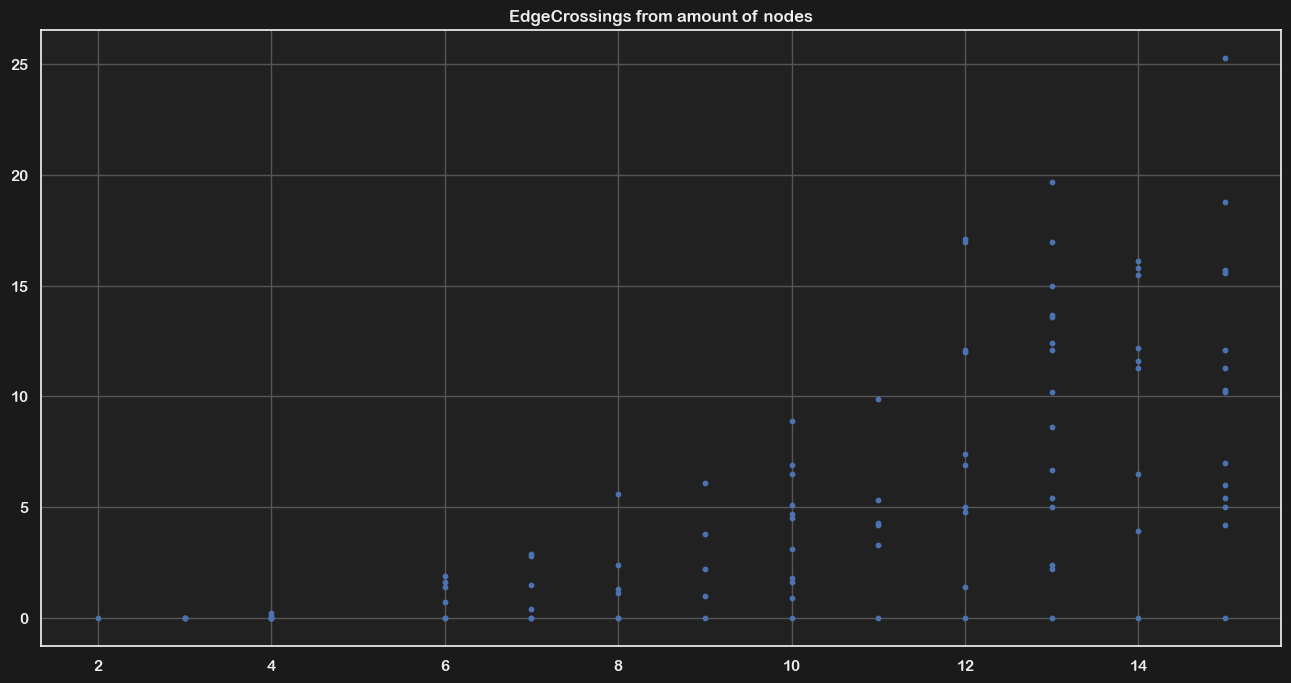

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))
plt.scatter(x=meanAns['n'], y=meanAns['edgeCrossings'], s=10)
plt.title("EdgeCrossings from amount of nodes")
plt.show()

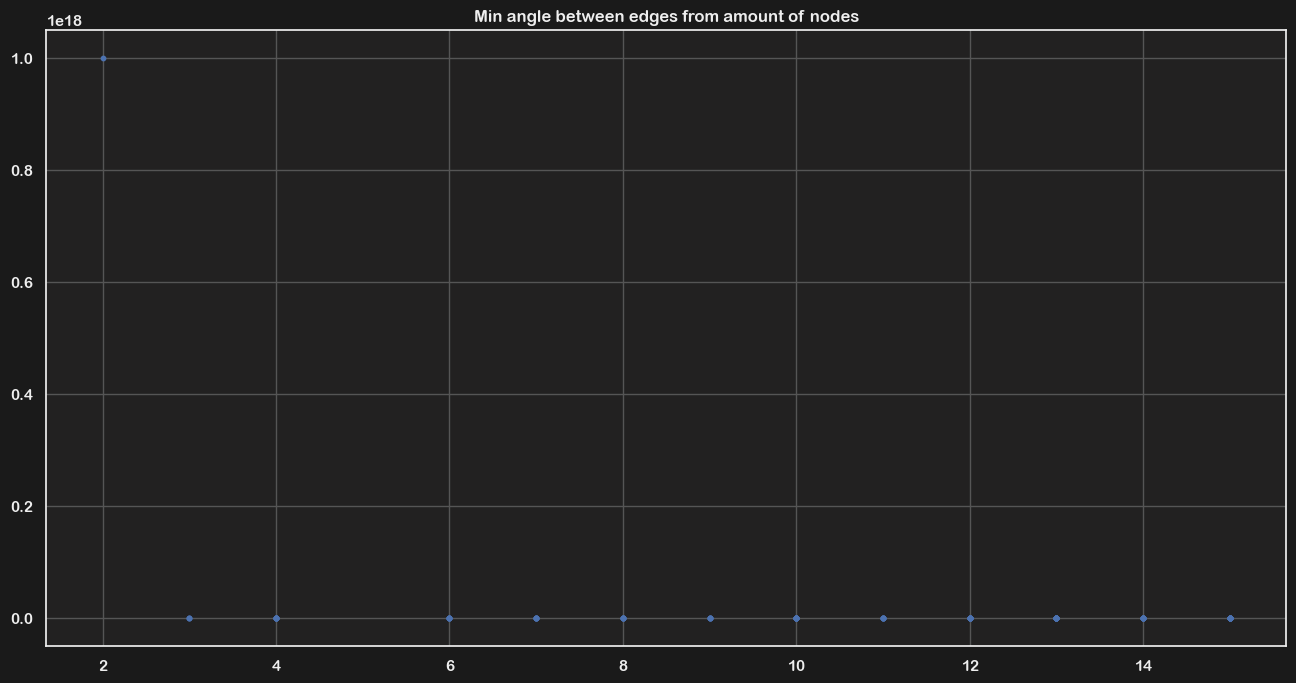

In [8]:
plt.figure(figsize=(16, 8))
plt.scatter(x=meanAns['n'], y=meanAns['minAngle'], s=10, alpha=1)
plt.title("Min angle between edges from amount of nodes")
plt.show()

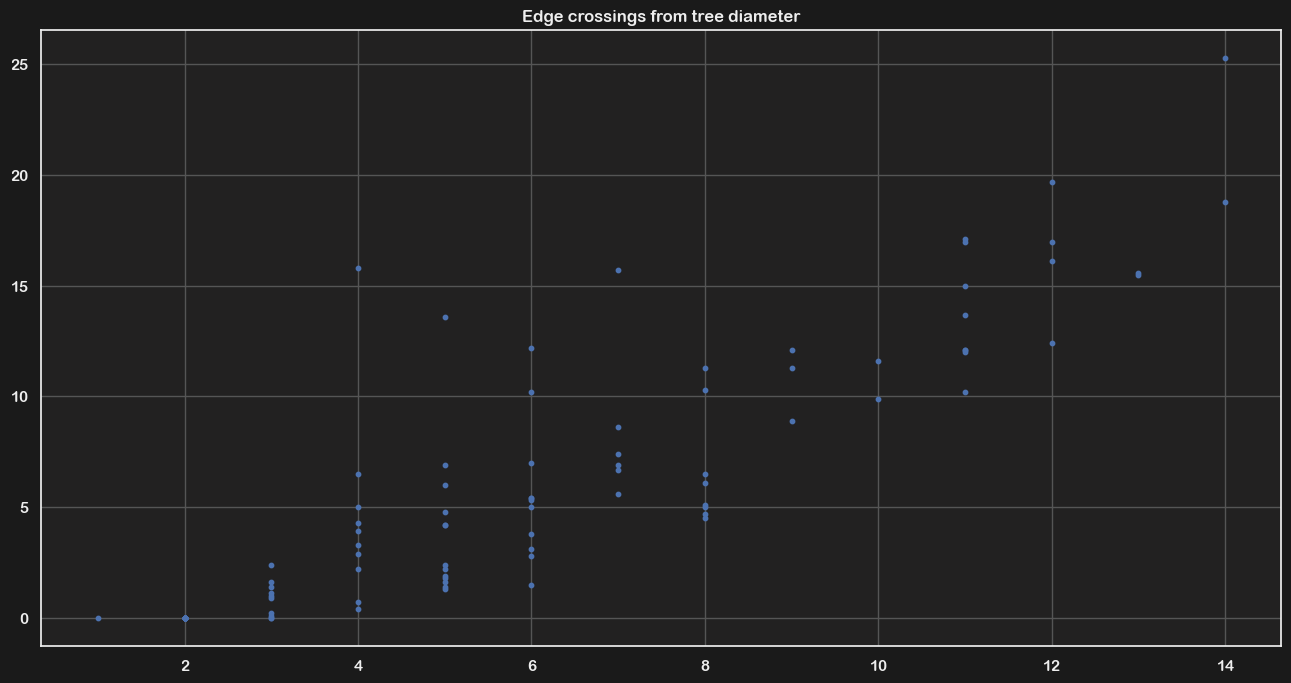

In [9]:
plt.figure(figsize=(16, 8))
plt.scatter(x=meanAns['diameter'], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from tree diameter")
plt.show()


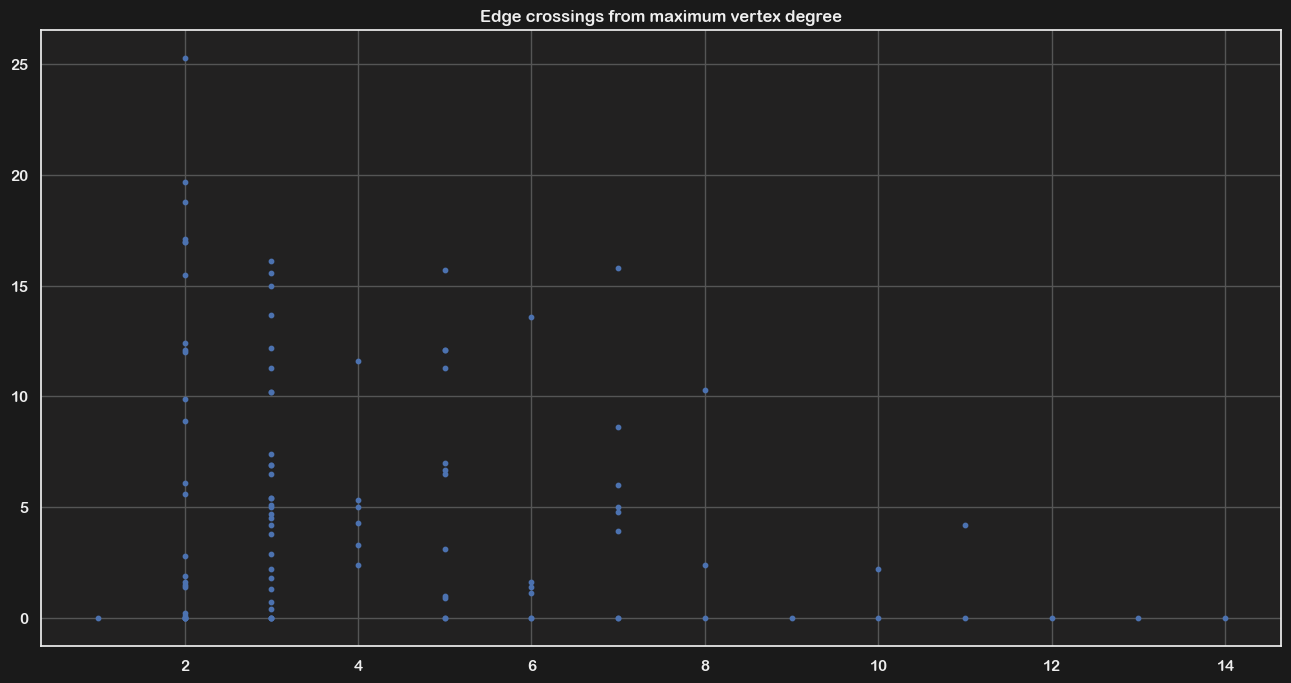

In [10]:
plt.figure(figsize=(16, 8))
plt.scatter(x=meanAns['top_degrees'].str[0], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from maximum vertex degree")
plt.show()


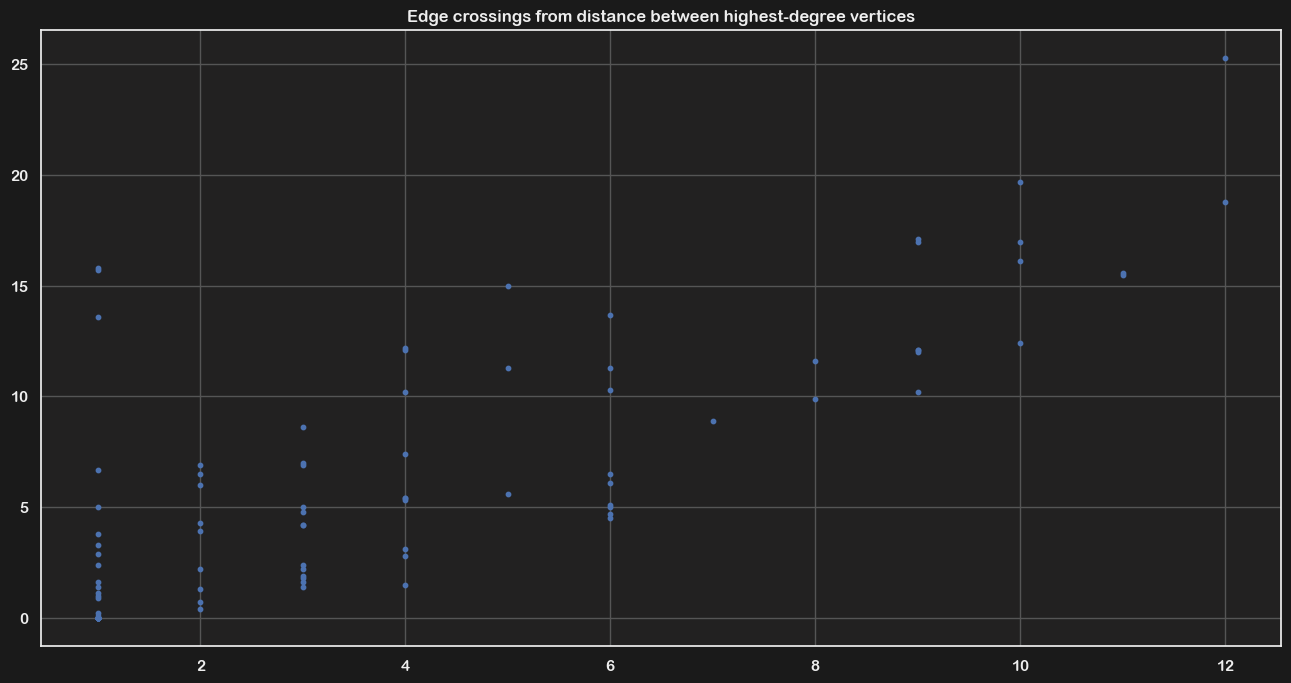

In [11]:
plt.figure(figsize=(16, 8))
plt.scatter(x=meanAns['top_distance'], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from distance between highest-degree vertices")
plt.show()


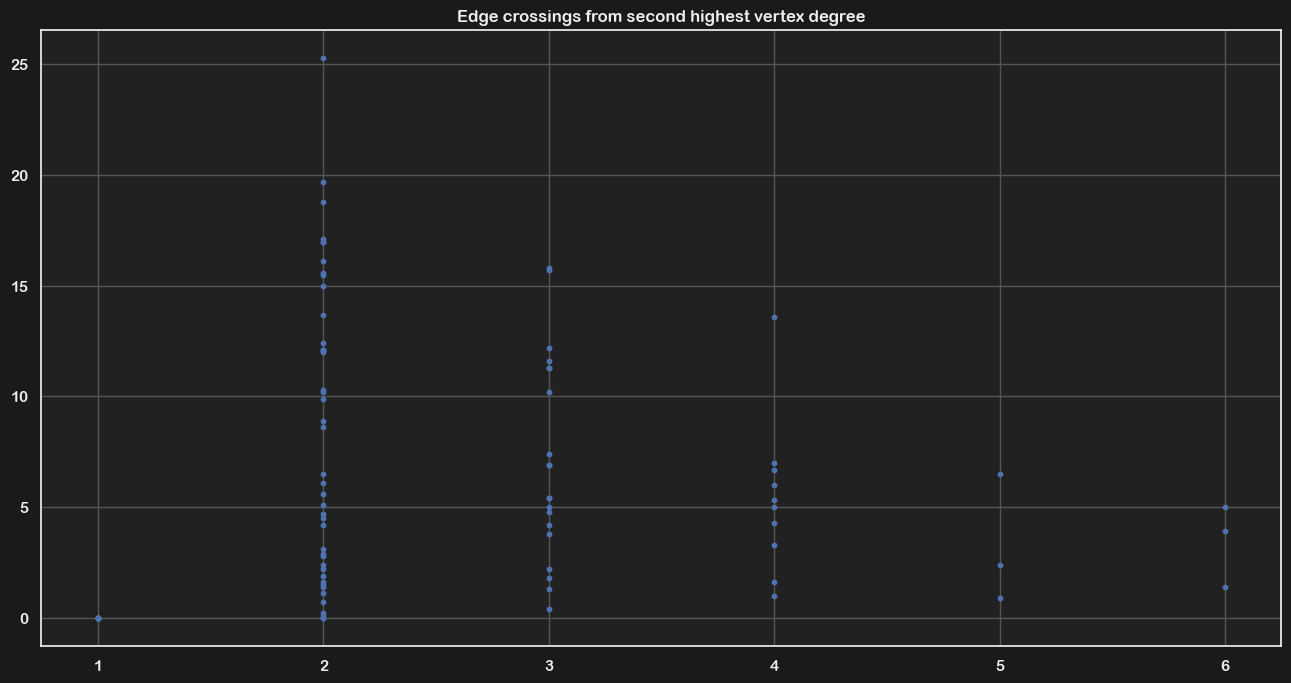

In [12]:
plt.figure(figsize=(16, 8))
plt.scatter(x=meanAns['top_degrees'].str[1], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from second highest vertex degree")
plt.show()


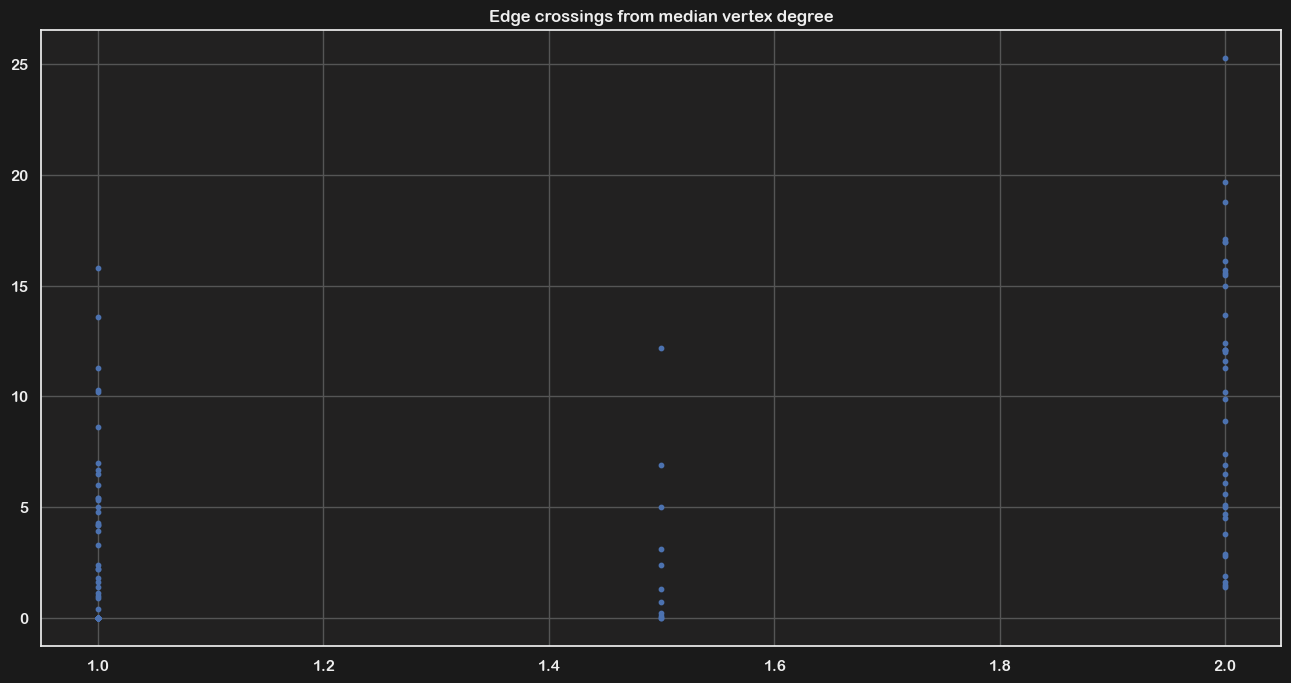

In [13]:
plt.figure(figsize=(16, 8))
plt.scatter(x=meanAns['median_degree'], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from median vertex degree")
plt.show()


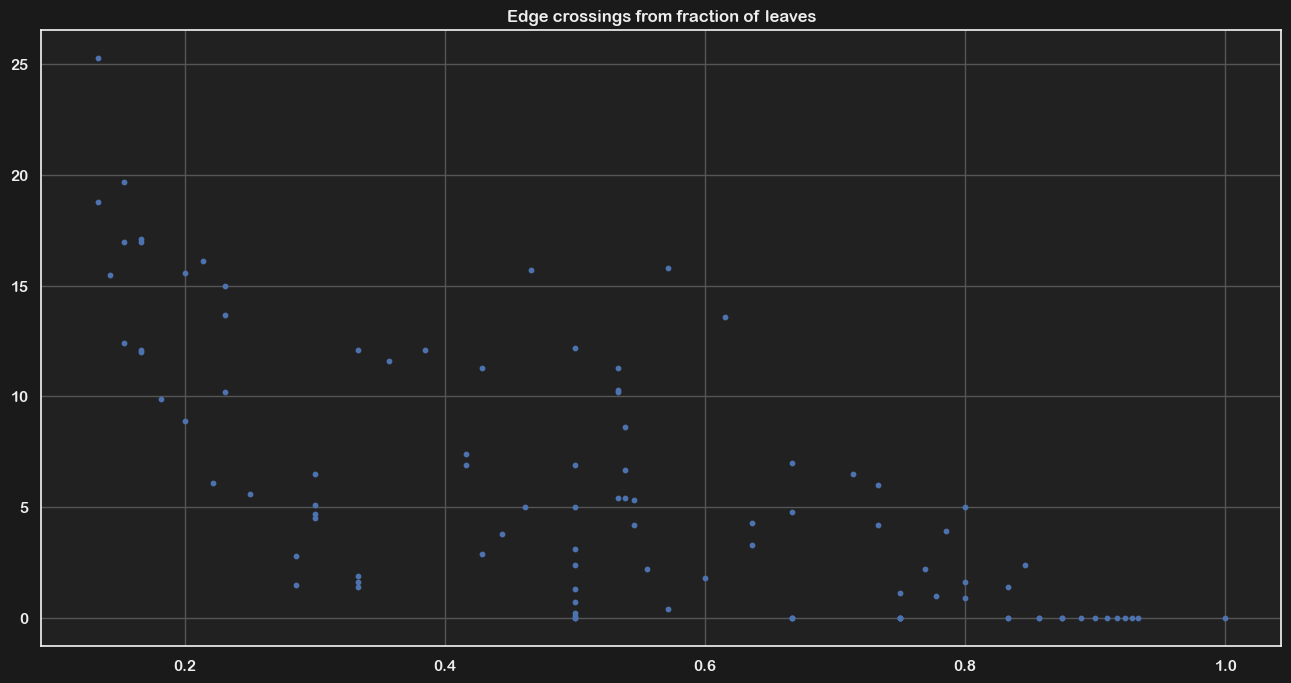

In [14]:
plt.figure(figsize=(16, 8))
plt.scatter(x=meanAns['leaf_fraction'], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from fraction of leaves")
plt.show()


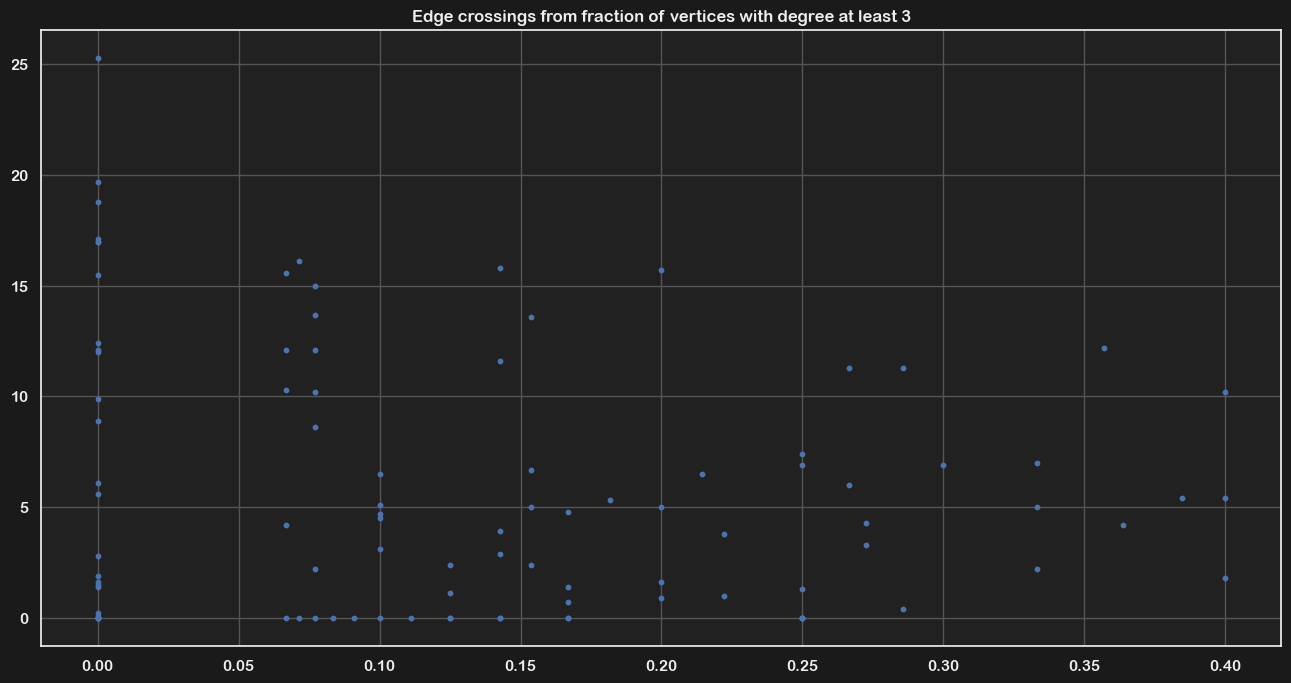

In [15]:
plt.figure(figsize=(16, 8))
plt.scatter(x=meanAns['branch_fraction'], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from fraction of vertices with degree at least 3")
plt.show()


In [16]:
graphs = dataDf

flags = [
    "--graph", "",
    "--algo", "far",
    "--initial-placement", "random",
    "--space", "hyperbolic",
    "--dim", "2",
    "--borderPolicy", "poly",
    "--projection", "kleinOrthogonal",
    "--2d",
    "--FS", "10, 10",
    "--dataset", str(dataset_path),
    "--output", "out/notebook/far/metrics_from_tree/graph.json",
]

algoFlags = ["--C", "1.0", "--I", "500"]
borderFlags = ["--S", "5,5"]
rnd = [1543, 42, 179, 57, 211, 307, 401, 503, 601, 907]
batchSize = 10

compileGd(mainPath, buildDir="build/release", buildType="Release")
releaseBinary = mainPath / "build" / "release" / "graph_drawing"

-- Configuring done (0.1s)
-- Generating done (0.0s)
-- Build files have been written to: /Users/user/Code/Repos/GraphDrawing/build/release
[100%] Built target graph_drawing


In [17]:
import tempfile
from tqdm.auto import tqdm

runs = []
for start in tqdm(range(0, len(graphs), batchSize)):
    batch = graphs.iloc[start:start + batchSize]
    graphNames = batch["name"].tolist()

    with tempfile.TemporaryDirectory(prefix="gd-trees-") as tmp:
        batchPath = Path(tmp) / "dataset.json"
        batchData = batch[["name", "nodes", "edges"]].to_dict("records")
        with open(batchPath, "w", encoding="utf-8") as f:
            json.dump(batchData, f)

        def flagsForRun(indices):
            for ind in indices:
                cur = list(flags)
                gdExperiments.setFlagValue(cur, "--graph", graphNames[ind // len(rnd)])
                gdExperiments.setFlagValue(cur, "--seed", rnd[ind % len(rnd)])
                gdExperiments.setFlagValue(cur, "--dataset", str(batchPath))
                yield cur

        res = runTests(
            mainPath,
            flags=flags,
            n=len(batch) * len(rnd),
            flagsForRun=flagsForRun,
            algoFlags=algoFlags,
            borderFlags=borderFlags,
            outDir=tmp,
            binary=releaseBinary,
        )

        res["name"] = [graphNames[i // len(rnd)] for i in range(len(res))]
        res["seed"] = [rnd[i % len(rnd)] for i in range(len(res))]
        res["run"] = [i % len(rnd) + 1 for i in range(len(res))]
        res.loc[res["returnCode"] != 0, list(gdExperiments.metricKeys)] = float("nan")
        res["jsonPath"] = None
        for runFlags in res["flags"]:
            gdExperiments.setFlagValue(runFlags, "--dataset", str(dataset_path))
            outputIndex = runFlags.index("--output")
            del runFlags[outputIndex:outputIndex + 2]

    runs.append(res)

ans = pd.concat(runs, ignore_index=True) if runs else pd.DataFrame()
if not ans.empty:
    graphColumns = ["name", "description", "gen_algo"] + list(properties.columns)
    ans = ans.merge(dataDf[graphColumns], on="name", how="left", validate="many_to_one")
ans

  1%|          | 37/5000 [01:07<2:30:39,  1.82s/it]


KeyboardInterrupt: 

In [31]:
if ans.empty:
    meanAns = pd.DataFrame()
else:
    meanAns = ans.groupby("name", as_index=False)[list(gdExperiments.metricKeys)].mean()
    meanAns = meanAns.merge(dataDf[graphColumns], on="name", how="left", validate="one_to_one")
meanAns

,name,volume,minVertexDist,maxVertexDist,avgVertexDist,minEdgeVertexDist,edgeCrossings,minAngle,maxAngle,density,...,description,gen_algo,n,diameter,top_vertices,top_degrees,top_distance,median_degree,leaf_fraction,branch_fraction
0,tree_000010,78.539816,0.0,9.622504,5.874246,0.0,331.5,0.000000,3.024314,0.738479,...,path tree with 58 vertices,path,58,57,"[36, 28]","[2, 2]",55.0,2.0,0.034483,0.000000
1,tree_000021,78.539816,0.0,9.622504,5.977495,0.0,0.0,0.000000,3.139561,0.853070,...,star tree with 67 vertices,star,67,2,"[22, 0]","[66, 1]",1.0,1.0,0.985075,0.014925
2,tree_000033,78.539816,0.0,9.622504,5.967730,0.0,0.0,0.000000,3.139656,0.980394,...,star tree with 77 vertices,star,77,2,"[40, 0]","[76, 1]",1.0,1.0,0.987013,0.012987
3,tree_000038,78.539816,0.0,9.622504,5.756850,0.0,302.7,0.001867,3.105711,0.980394,...,binary tree with 77 vertices,binary,77,11,"[7, 3]","[3, 3]",9.0,1.0,0.506494,0.480519
4,tree_000046,78.539816,0.0,9.622504,6.041556,0.0,28.7,0.015782,2.836884,0.229183,...,path tree with 18 vertices,path,18,17,"[14, 11]","[2, 2]",15.0,2.0,0.111111,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,tree_099954,78.539816,0.0,9.622504,5.745371,0.0,384.2,0.000000,3.119281,1.005859,...,recursive tree with 79 vertices,recursive,79,15,"[76, 47]","[6, 6]",1.0,2.0,0.468354,0.240506
9996,tree_099972,78.539816,0.0,9.622504,5.799566,0.0,214.4,0.000000,3.113469,0.738479,...,recursive tree with 58 vertices,recursive,58,10,"[50, 24]","[9, 8]",2.0,1.0,0.517241,0.241379
9997,tree_099979,78.539816,0.0,9.622504,5.907505,0.0,318.9,0.000000,3.135166,0.929465,...,double_hub tree with 73 vertices,double_hub,73,39,"[46, 13]","[35, 2]",37.0,2.0,0.479452,0.013699
9998,tree_099984,78.539816,0.0,9.622504,5.967863,0.0,289.5,0.000000,3.139733,1.094986,...,double_hub tree with 86 vertices,double_hub,86,3,"[17, 31]","[53, 33]",1.0,1.0,0.976744,0.023256


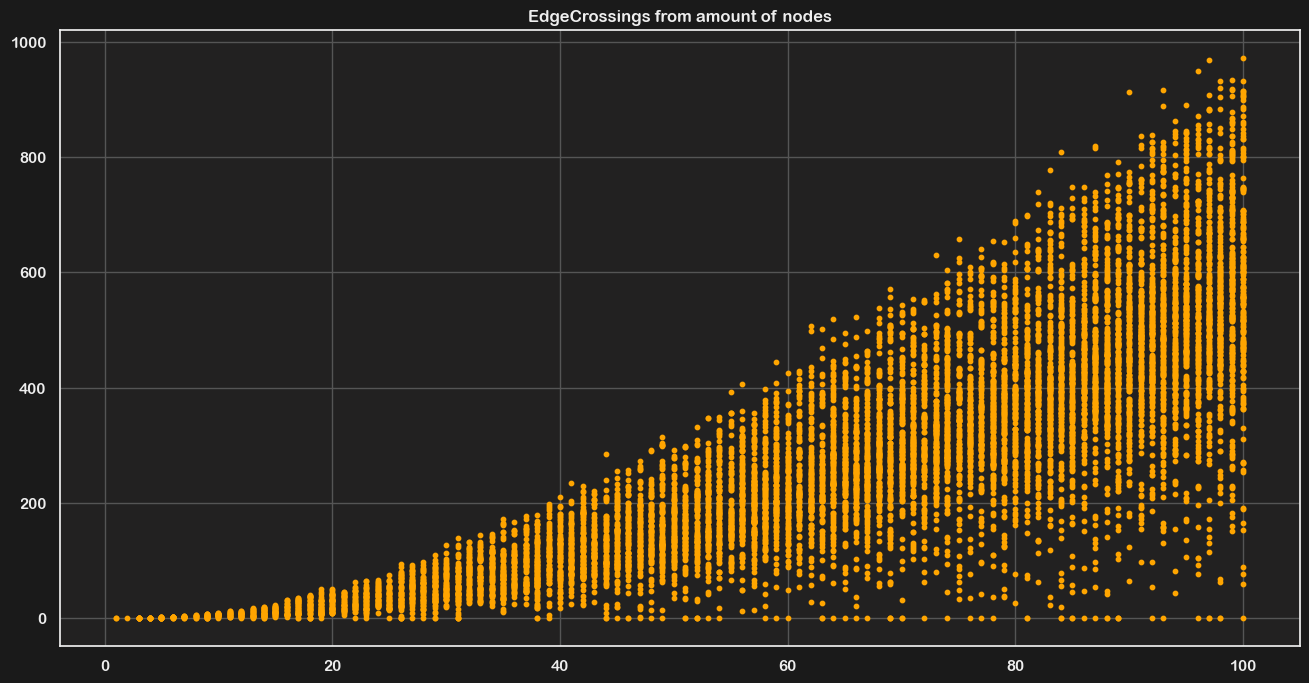

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))
plt.scatter(color="orange", x=meanAns['n'], y=meanAns['edgeCrossings'], s=10)
plt.title("EdgeCrossings from amount of nodes")
plt.show()

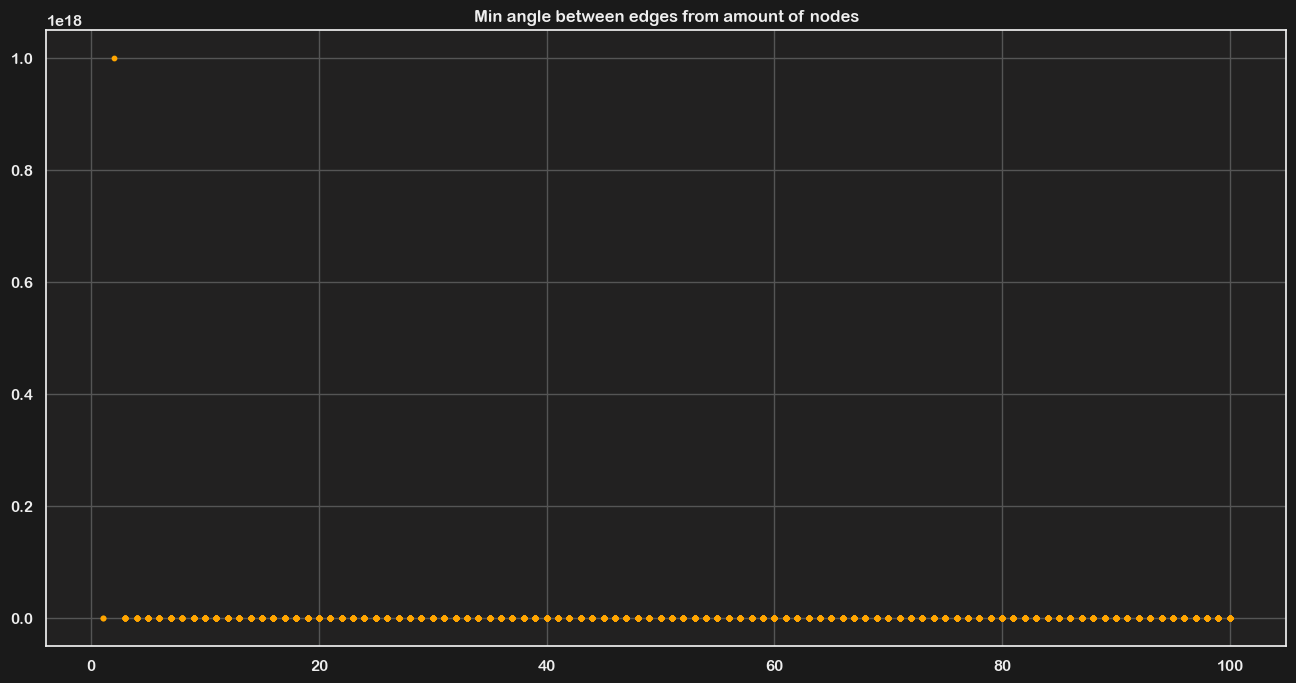

In [33]:
plt.figure(figsize=(16, 8))
plt.scatter(color="orange", x=meanAns['n'], y=meanAns['minAngle'], s=10, alpha=1)
plt.title("Min angle between edges from amount of nodes")
plt.show()

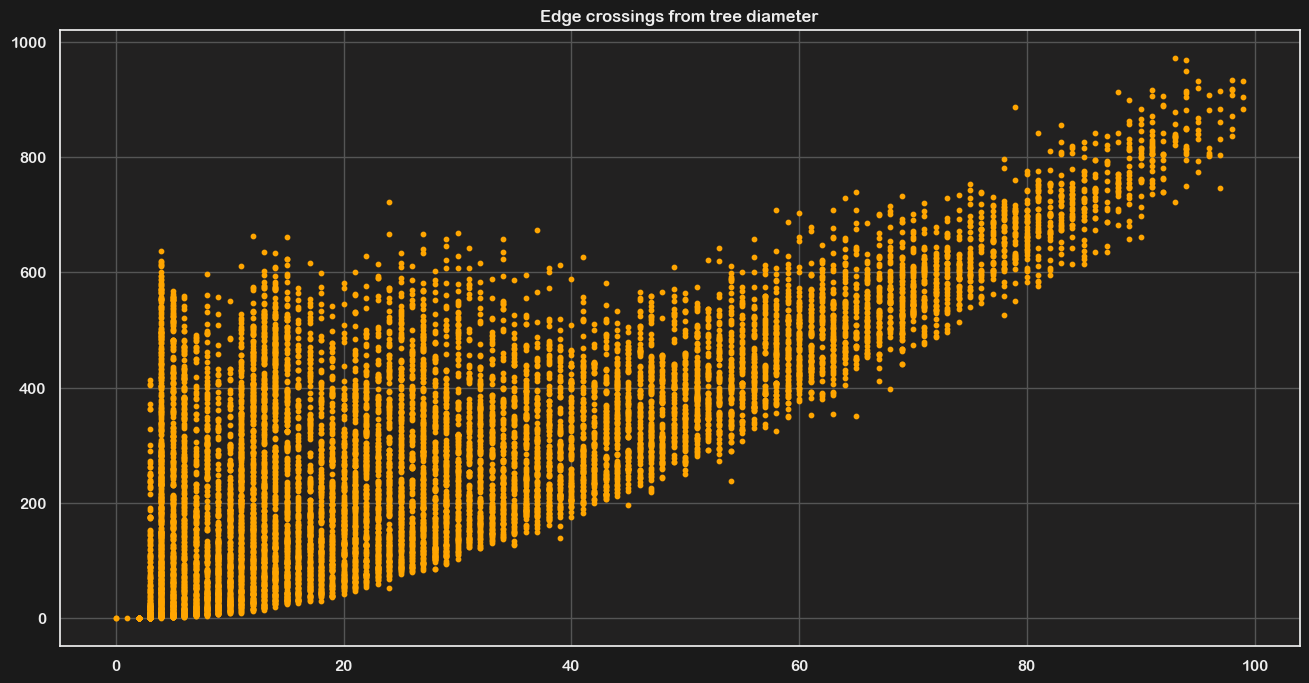

In [34]:
plt.figure(figsize=(16, 8))
plt.scatter(color="orange", x=meanAns['diameter'], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from tree diameter")
plt.show()


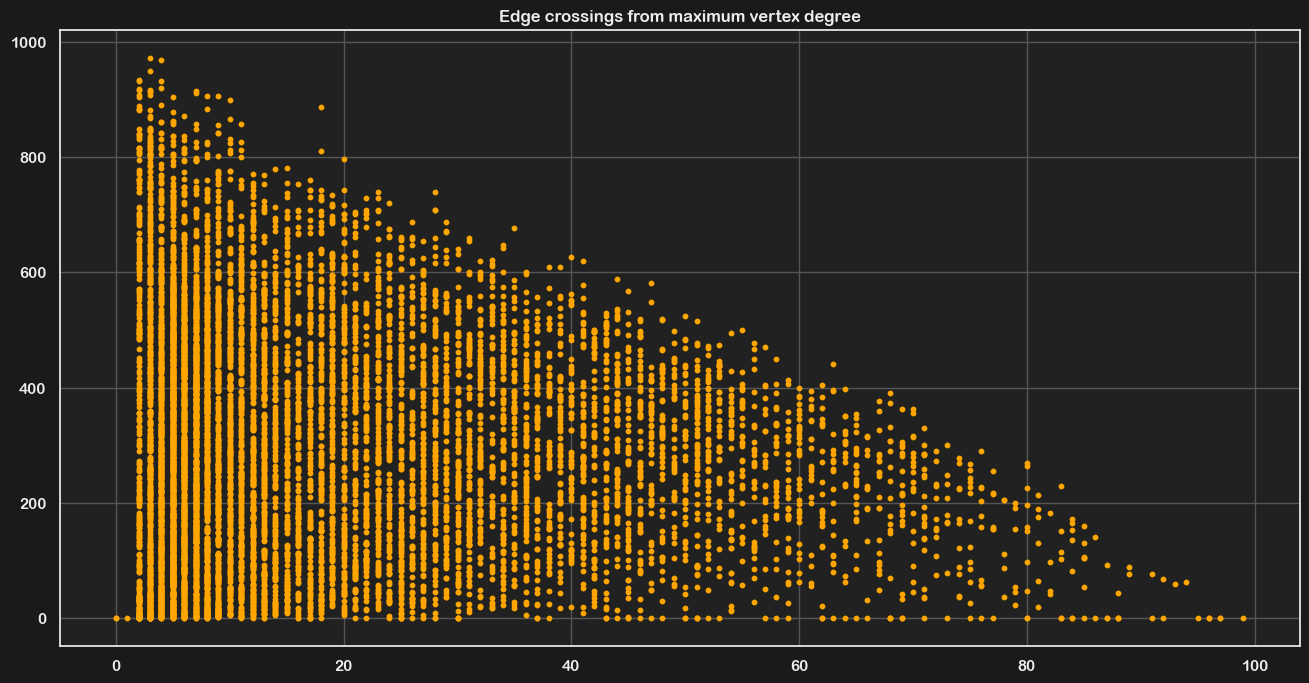

In [35]:
plt.figure(figsize=(16, 8))
plt.scatter(color="orange", x=meanAns['top_degrees'].str[0], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from maximum vertex degree")
plt.show()


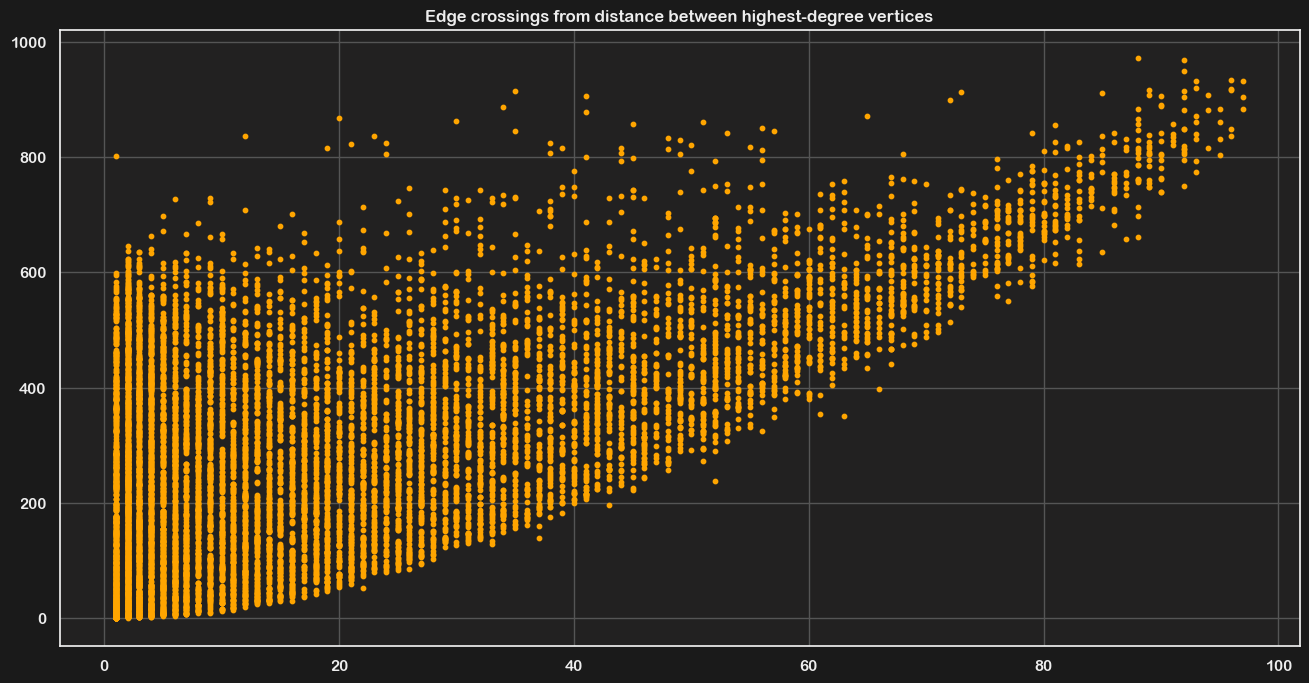

In [36]:
plt.figure(figsize=(16, 8))
plt.scatter(color="orange", x=meanAns['top_distance'], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from distance between highest-degree vertices")
plt.show()


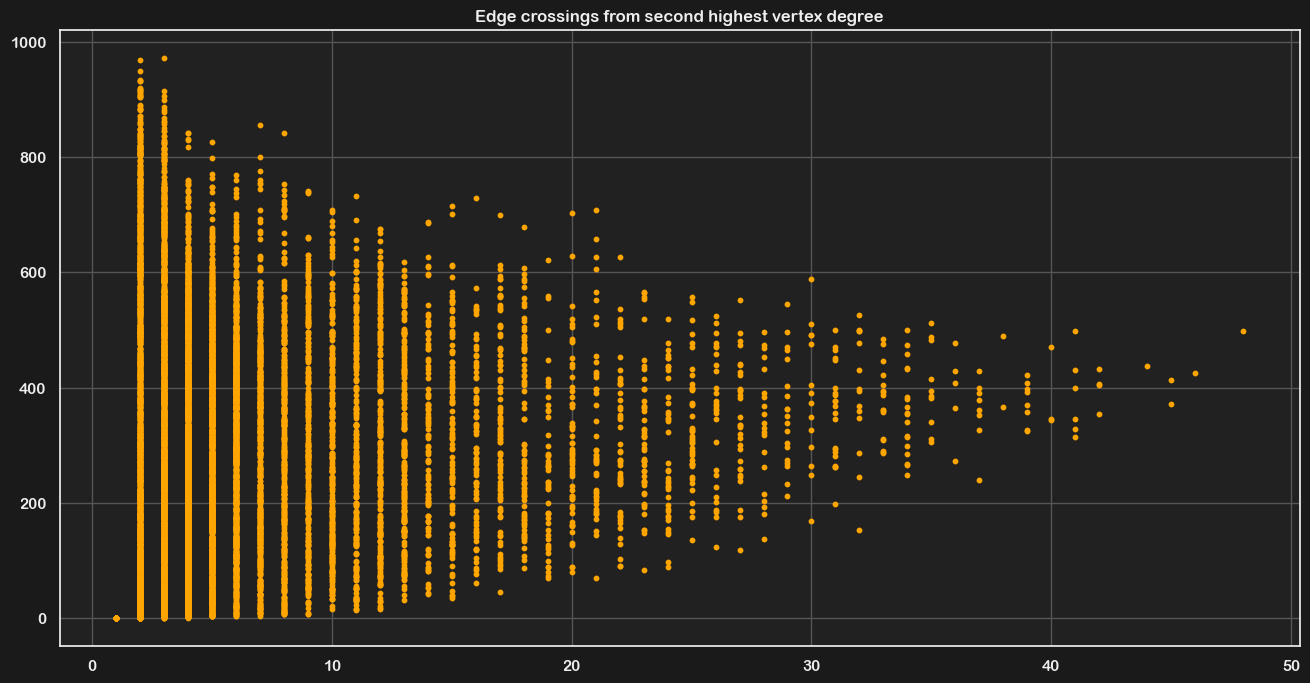

In [37]:
plt.figure(figsize=(16, 8))
plt.scatter(color="orange", x=meanAns['top_degrees'].str[1], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from second highest vertex degree")
plt.show()


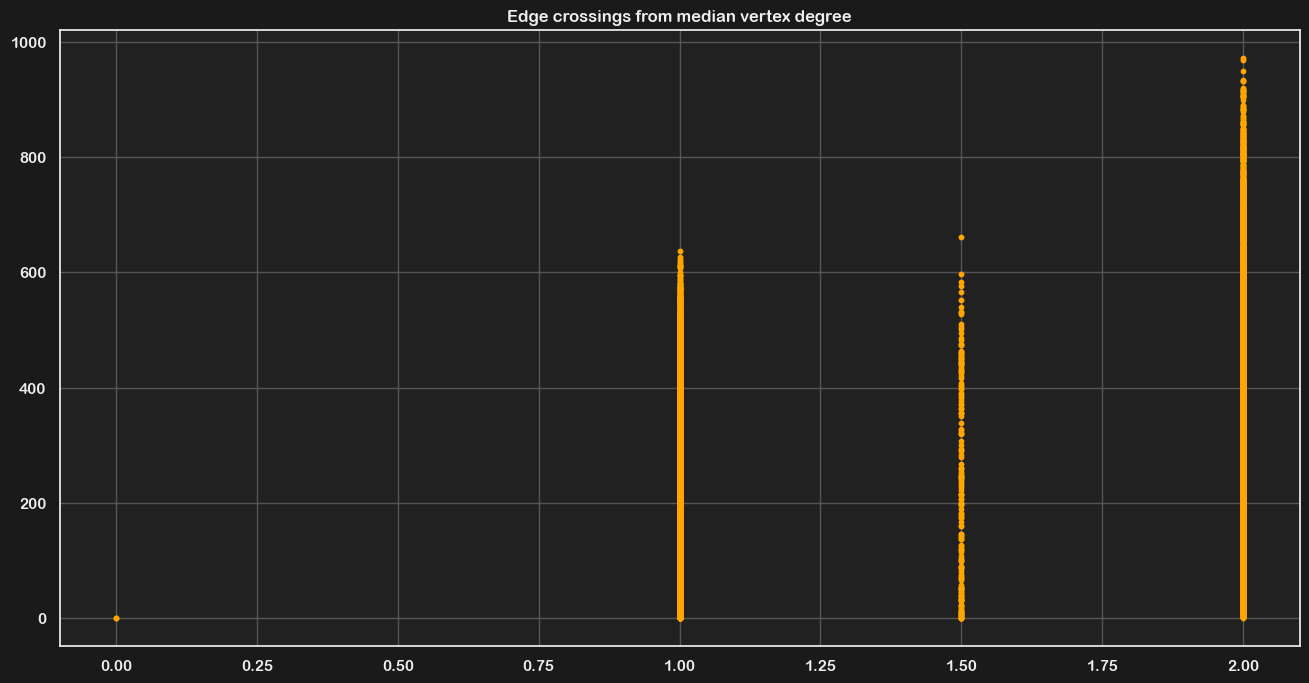

In [38]:
plt.figure(figsize=(16, 8))
plt.scatter(color="orange", x=meanAns['median_degree'], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from median vertex degree")
plt.show()


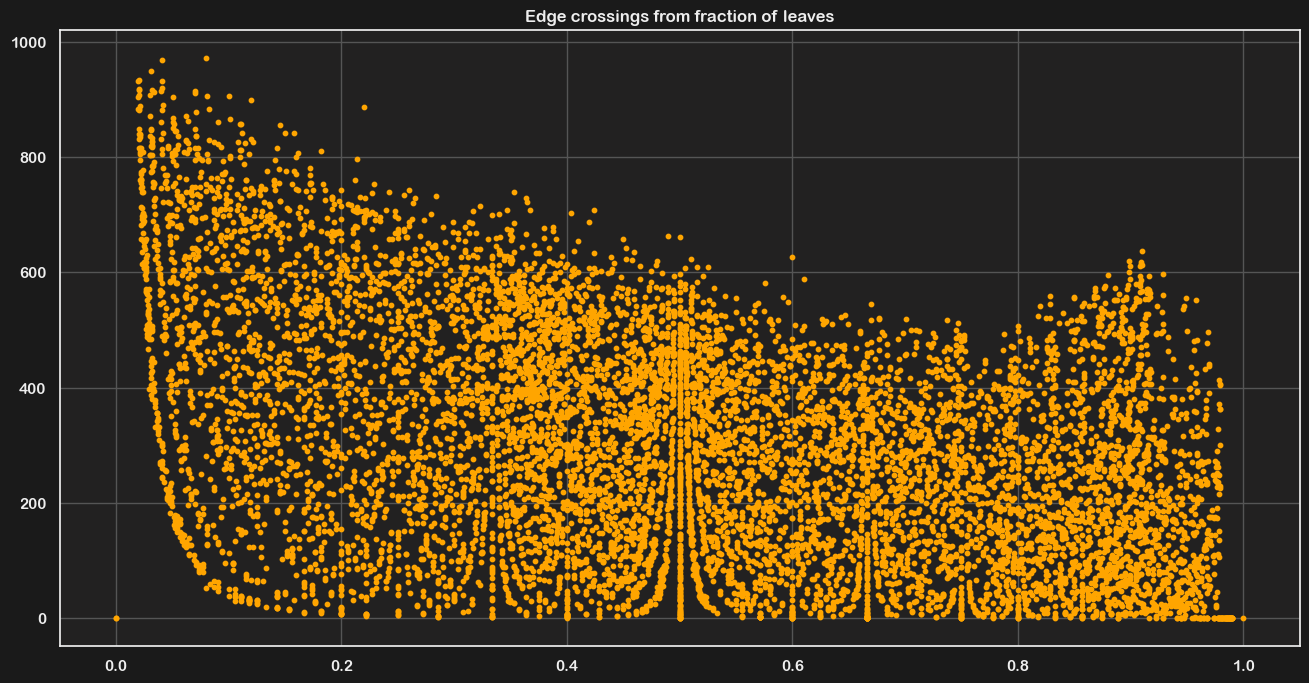

In [39]:
plt.figure(figsize=(16, 8))
plt.scatter(color="orange", x=meanAns['leaf_fraction'], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from fraction of leaves")
plt.show()


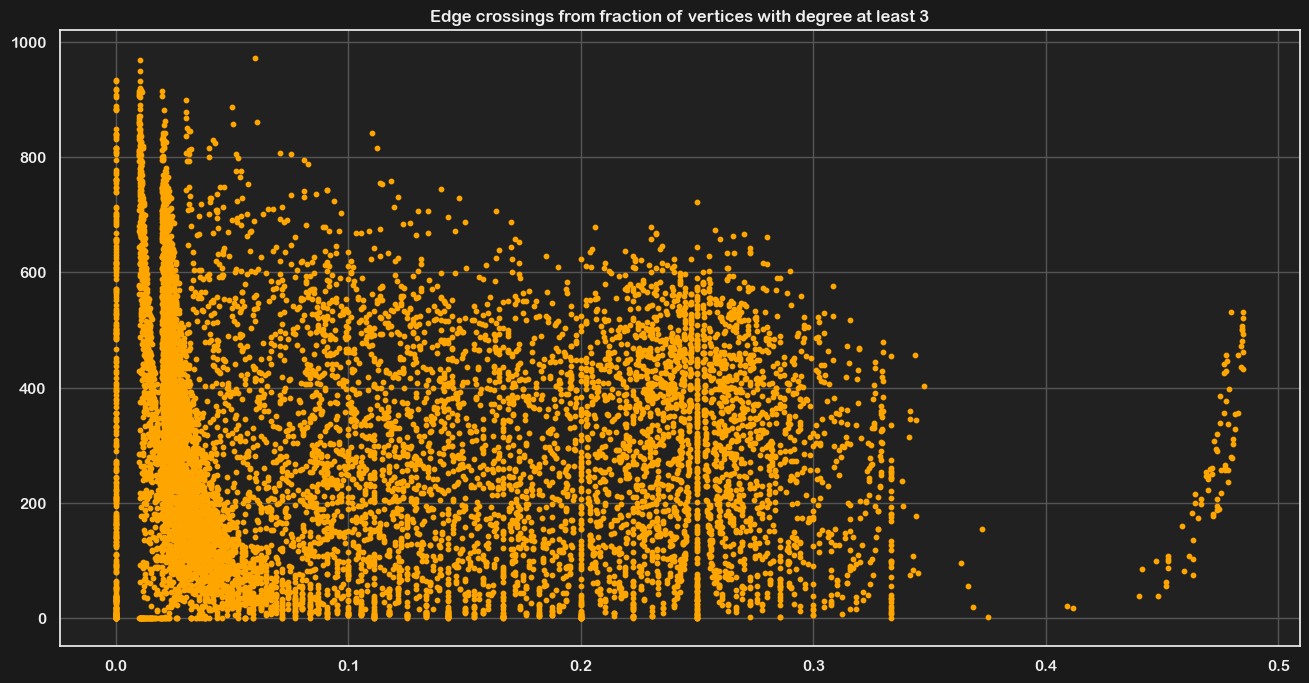

In [41]:
plt.figure(figsize=(16, 8))
plt.scatter(color="orange", x=meanAns['branch_fraction'], y=meanAns['edgeCrossings'], s=10, alpha=1)
plt.title("Edge crossings from fraction of vertices with degree at least 3")
plt.show()


In [42]:
import base64
from datetime import datetime

notebookPath = mainPath / "testing" / "metrics_from_tree_type.ipynb"
outDir = mainPath / "testsOuts" / datetime.now().strftime("%Y-%m-%d_%H-%M-%S-%f")
outDir.mkdir(parents=True)

ans.to_csv(outDir / "ans.csv", index=False)
meanAns.to_csv(outDir / "meanAns.csv", index=False)

with open(notebookPath, encoding="utf-8") as f:
    savedNotebook = json.load(f)

imageCount = 0
for cellIndex, cell in enumerate(savedNotebook["cells"]):
    if cell.get("cell_type") != "code" or "plt." not in "".join(cell.get("source", [])):
        continue
    for output in cell.get("outputs", []):
        png = output.get("data", {}).get("image/png")
        if png:
            imageCount += 1
            if isinstance(png, list):
                png = "".join(png)
            (outDir / f"graph_{imageCount:02d}_cell_{cellIndex}.png").write_bytes(base64.b64decode(png))
